In [1]:
import os
import torch
from botorch import fit_gpytorch_mll
import botorch_tool
import copy
from botorch.sampling.normal import SobolQMCNormalSampler
from botorch.utils.transforms import unnormalize, normalize, standardize
import numpy as np 
import pandas as pd
import json 
from matplotlib import pyplot as plt 
import pickle
from botorch.utils.transforms import standardize
from botorch.models.transforms.outcome import Standardize
from copy import copy 

torch.set_default_dtype(torch.float64)

tkwargs = {
    "dtype": torch.double,
    "device": torch.device("cuda" if torch.cuda.is_available() else "cpu")
}

BATCH_NUM = 4

In [2]:
exp_data = []
for BATCH_NUM_tmp in range(BATCH_NUM + 1):
    if BATCH_NUM_tmp == 0:
        with open(f"./all_experiment_{BATCH_NUM_tmp}.json", "r") as f:
            exp_data.append(pd.DataFrame(json.load(f)))
    else:
        with open(f"./all_experiment_{BATCH_NUM_tmp}.json", "r") as f:
            test_data = pd.DataFrame(json.load(f))
        temp_total = []
        for i in range(int(len(test_data)/2)):
            temp = copy(test_data.iloc[2*i])
            if temp["substance1"] == "Cu" and temp["substance2"] == "Mn" and temp["volume1"] == 19.18:
                # pass the reference data 
                pass
            else:
                temp["mean_S"] = test_data["mean_S"][2*i:2*i+2].values.mean()
                temp["variance_S"] = test_data["mean_S"][2*i:2*i+2].values.var() + test_data["variance_S"][2*i:2*i+2].values.mean()
                
                temp["mean_current"] = test_data["mean_current"][2*i:2*i+2].values.mean()
                temp["variance_current"] = test_data["mean_current"][2*i:2*i+2].values.var() + test_data["variance_current"][2*i:2*i+2].values.mean()
                temp_total.append(temp)
                
        temp_total = pd.DataFrame(temp_total).reset_index(drop=True)
        exp_data.append(temp_total)
        
exp_data = pd.concat(exp_data).sort_values(by=["substance1", "substance2", "volume1"]).reset_index(drop=True)

if not (exp_data.index.astype("int") == np.arange(len(exp_data))).all():
    raise ValueError("the index of the expeirments is not right")

# add noise from Pt experiments
exp_data["variance_S"] = exp_data["variance_S"] + 1.6 # intrinsic noise 
exp_data["variance_current"] = exp_data["variance_current"] + 198.53 # intrinsic noise 
temp_total

,substance1,substance2,volume1,volume2,voltage,mean_S,variance_S,mean_current,variance_current
0,Co,Y,16.89,3.11,-2.87,11.234835,0.923244,128.902588,205.799551
1,Cu,Ni,19.50,0.50,-2.99,13.264308,0.429981,100.508147,10.394024
2,Cu,Sc,19.50,0.50,-2.99,13.355397,0.437814,106.556269,63.013104
3,Cu,Y,19.50,0.50,-2.99,12.780212,1.088007,93.727721,261.757311
4,Fe,Cu,0.50,19.50,-2.71,12.152012,0.139312,112.312104,284.932329


In [3]:
test_data

,substance1,substance2,volume1,volume2,voltage,mean_S,variance_S,mean_current,variance_current
0,Co,Y,18.09,1.91,-2.81,12.205856,0.370982,139.601336,0.176125
1,Co,Y,18.09,1.91,-2.88,12.980902,0.670967,137.438230,0.225700
2,Cu,Mn,19.18,0.82,-2.66,14.541227,0.322711,102.871619,0.129378
3,Cu,Mn,19.18,0.82,-2.52,13.375654,0.246663,144.913022,0.084438
4,Cu,Ni,17.78,2.22,-2.69,10.124673,0.227794,133.320367,0.192774
5,Cu,Ni,17.78,2.22,-2.99,11.024686,0.178547,113.031720,0.147875
6,Cu,Sc,11.66,8.34,-2.99,11.307374,0.342968,84.358164,0.057676
7,Cu,Sc,11.66,8.34,-2.99,11.307374,0.342968,86.082037,0.133407
8,Cu,Y,17.77,2.23,-2.99,13.649802,0.786798,93.328447,0.035032
9,Cu,Y,17.77,2.23,-2.99,13.352426,0.923306,90.969533,0.020519


In [4]:
metal_combo_original = np.concatenate((exp_data["substance1"].values.reshape(-1,1), 
                                       exp_data["substance2"].values.reshape(-1,1)), axis = 1).astype("str")
metal_combo = (pd.read_csv("./selected_systems.csv", header = None).values)[list(range(7,12))]

len(metal_combo)

5

/home/xiangan/anaconda3/lib/python3.11/site-packages/botorch/models/utils/assorted.py:202: InputDataWarning: Input data is not standardized (mean = tensor([-1.8022]), std = tensor([0.0687])). Please consider scaling the input to zero mean and unit variance.
  warnings.warn(msg, InputDataWarning)
/home/xiangan/anaconda3/lib/python3.11/site-packages/linear_operator/utils/cholesky.py:40: NumericalWarning: A not p.d., added jitter of 1.0e-08 to the diagonal
  warnings.warn(


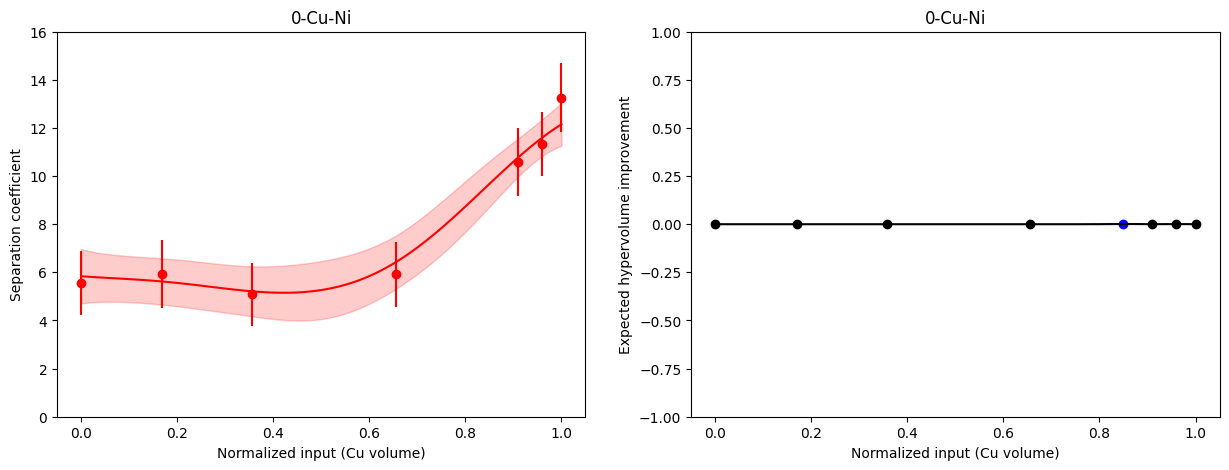

/home/xiangan/anaconda3/lib/python3.11/site-packages/botorch/models/utils/assorted.py:202: InputDataWarning: Input data is not standardized (mean = tensor([-0.1470]), std = tensor([0.2210])). Please consider scaling the input to zero mean and unit variance.
  warnings.warn(msg, InputDataWarning)
/home/xiangan/anaconda3/lib/python3.11/site-packages/linear_operator/utils/cholesky.py:40: NumericalWarning: A not p.d., added jitter of 1.0e-08 to the diagonal
  warnings.warn(


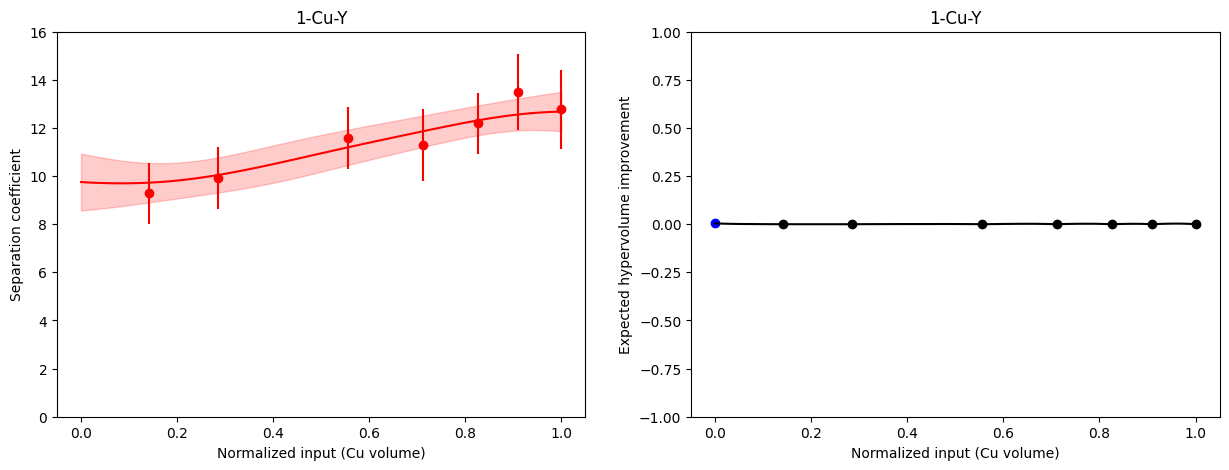

/home/xiangan/anaconda3/lib/python3.11/site-packages/botorch/models/utils/assorted.py:202: InputDataWarning: Input data is not standardized (mean = tensor([-0.1293]), std = tensor([0.1017])). Please consider scaling the input to zero mean and unit variance.
  warnings.warn(msg, InputDataWarning)
/home/xiangan/anaconda3/lib/python3.11/site-packages/linear_operator/utils/cholesky.py:40: NumericalWarning: A not p.d., added jitter of 1.0e-08 to the diagonal
  warnings.warn(


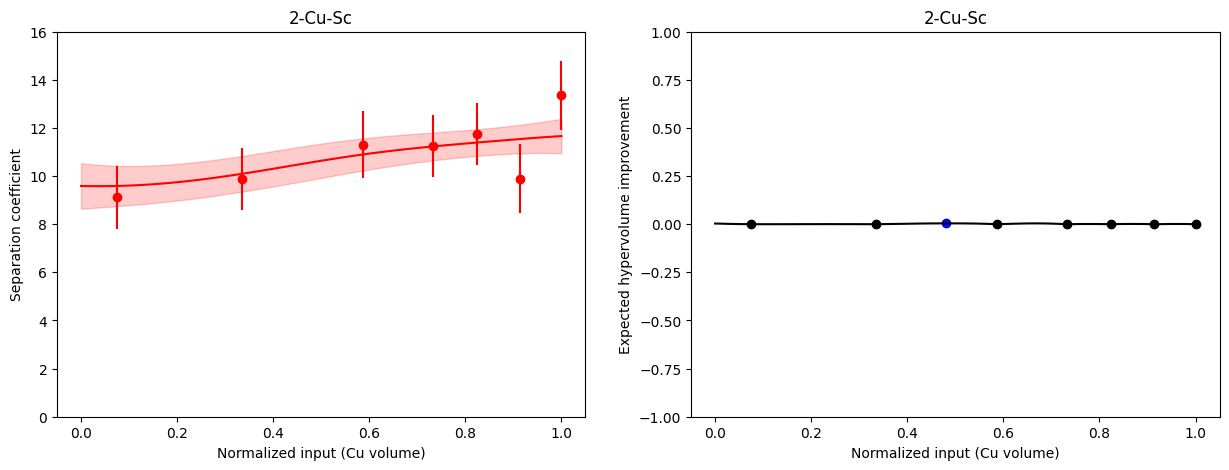

/home/xiangan/anaconda3/lib/python3.11/site-packages/botorch/models/utils/assorted.py:202: InputDataWarning: Input data is not standardized (mean = tensor([-1.1954]), std = tensor([0.1844])). Please consider scaling the input to zero mean and unit variance.
  warnings.warn(msg, InputDataWarning)
/home/xiangan/anaconda3/lib/python3.11/site-packages/linear_operator/utils/cholesky.py:40: NumericalWarning: A not p.d., added jitter of 1.0e-08 to the diagonal
  warnings.warn(


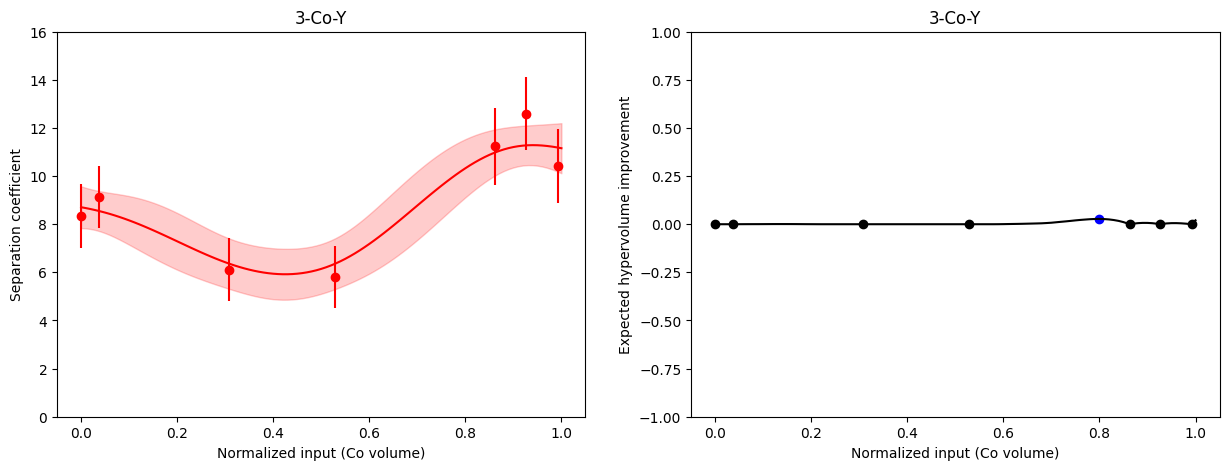

/home/xiangan/anaconda3/lib/python3.11/site-packages/botorch/models/utils/assorted.py:202: InputDataWarning: Input data is not standardized (mean = tensor([0.2278]), std = tensor([0.1734])). Please consider scaling the input to zero mean and unit variance.
  warnings.warn(msg, InputDataWarning)
/home/xiangan/anaconda3/lib/python3.11/site-packages/linear_operator/utils/cholesky.py:40: NumericalWarning: A not p.d., added jitter of 1.0e-08 to the diagonal
  warnings.warn(


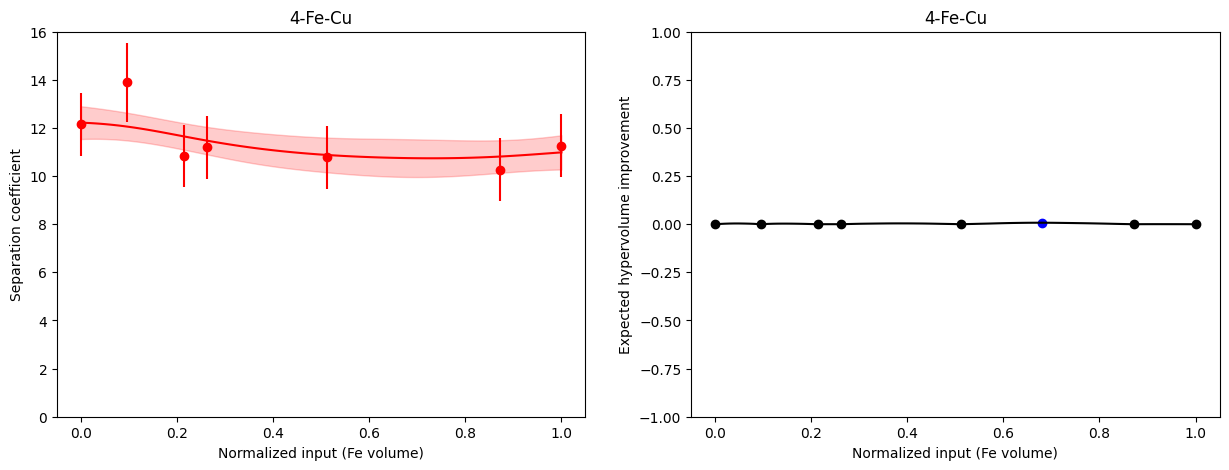

In [5]:
from botorch.acquisition.monte_carlo import qNoisyExpectedImprovement

np.random.seed(42)
torch.manual_seed(42)

model_total = {}
y_train_total = []
x_train_total = []
failures = []


for i in range(5):
    # get the selected index
    selected_index = np.where((metal_combo_original == metal_combo[i]).all(axis = 1) == True)[0]
    
    # read in the data
    x = []
    y_mean = []
    y_var = []
    
    # read in the data 
    for j in selected_index:
        x.append((exp_data.iloc[j]["volume1"]/20 - 0.025)/0.95)
        y_mean.append(exp_data.iloc[j]["mean_S"])
        y_var.append(exp_data.iloc[j]["variance_S"])
            
    # process the data input numpy array
    x = np.array(x).reshape(-1,1)
    y_mean = np.array(y_mean).reshape(-1,1)
    y_var = np.array(y_var).reshape(-1,1)
    
    # if the data is not empty, perform machine learning
    if len(x)>0:
        # initialize the machine learning models for 
        train_x = torch.tensor(x).reshape(-1,1)
        train_y = torch.tensor(np.concatenate([y_mean], axis = 1))
        train_y_var = torch.tensor(np.concatenate([y_var], axis = 1))
        
        # add the data to the whole data set 
        y_train_total.append(train_y)
        x_train_total.append(train_x)
        # initialize the model 
        mll, model = botorch_tool.tools.initialize_heter_noise_model(train_x = train_x,
                                                                     train_obj = train_y,
                                                                     train_obj_var = train_y_var)
        # fit the model
        try:
            fit_gpytorch_mll(mll)
        except:
            print(f"fitting noiseless model for combination {i}")
            failures.append(i)
            try:
                # initialize the noiseless model (not really noiseless, because the noise is estimated by the means)
                mll, model = botorch_tool.tools.initialize_noiseless_model(train_x = train_x,
                                                                           train_obj = train_y)
                fit_gpytorch_mll(mll)
            except:
                raise ValueError(f"model fitting failed on combination {i}!")
        
        # show the prediction of the machine learning models
        x_plot = torch.tensor(np.linspace(0,1,101))
        preidct = model.posterior(x_plot).mean.detach().numpy()
        std = np.sqrt(model.posterior(x_plot).variance.detach().numpy())
        substance1 = metal_combo[i,0]
        substance2 = metal_combo[i,1]

        # plot the results from the prediction 
        fig, axs = plt.subplots(1, 2, figsize=(15, 5))
        # plot the coefficient of H/D splitting 
        axs[0].plot(x_plot, preidct[:,0], color = "red")
        axs[0].fill_between(x_plot, preidct[:,0] + std[:,0], preidct[:,0] - std[:,0],color='red', alpha=0.2)
        axs[0].scatter(train_x, 
                       train_y[:,0],
                       color = "red")
        axs[0].errorbar(train_x.flatten(), 
                        train_y[:,0].flatten(), 
                        yerr = np.sqrt(train_y_var[:,0].flatten()), 
                        xerr = None,  
                        color = "red",
                        ls='none')
        axs[0].set_xlabel(f"Normalized input ({substance1} volume)")
        axs[0].set_ylabel("Separation coefficient")
        axs[0].set_ylim(0, 16)
        axs[0].set_title(f"{i}-" + substance1 + "-" + substance2)
        
        # plot the acquisition according to the current model 
        # show the plot for the fitness function 
        sampler = SobolQMCNormalSampler(sample_shape=torch.Size([1024]))
        acq_func = qNoisyExpectedImprovement(model, train_x, sampler)
        
        acq_values = acq_func(x_plot.reshape(-1, 1, 1)).detach().numpy().flatten()
        
        # show the plot for the second prediction 
        axs[1].plot(x_plot, acq_values, color = "black")
        
        axs[1].scatter(train_x, 
                       acq_func(train_x.reshape(-1,1,1)).detach().numpy().flatten(),
                       color = "black")
        
        max_index = np.argmax(acq_values)
        
        axs[1].scatter(x_plot[max_index], 
                       acq_values[max_index], 
                       color = "blue")
        
        axs[1].set_xlabel(f"Normalized input ({substance1} volume)")
        axs[1].set_ylabel("Expected hypervolume improvement")
        axs[1].set_ylim(-1, 1)
        axs[1].set_title(f"{i}-" + substance1 + "-" + substance2)

        plt.show()
        plt.close()
        
        # append the model to the total model list 
        model_total[f"{i}-" + substance1 + "-" + substance2] = model
    else:
        raise ValueError(i)

### design the new experiments

In [6]:
from botorch.acquisition import ExpectedImprovement
from botorch.optim import optimize_acqf

np.random.seed(42)
torch.manual_seed(42)

# get total observations
obs_total = torch.concat(y_train_total, axis = 0)
best_value = obs_total.max()

# get the bounds for the optimization 
bounds = torch.stack([torch.zeros(1), torch.ones(1)])
candidate_total = {}

count = 0
# get the candidate for each model 
for model_key, model_val in model_total.items():
    sampler = SobolQMCNormalSampler(sample_shape=torch.Size([1024]))
    acq_func = qNoisyExpectedImprovement(
        model_val, x_train_total[count], sampler)
    
    candidate, expected_y = optimize_acqf(
        acq_function=acq_func,
        bounds=bounds,
        q=1,
        num_restarts=200,
        raw_samples=1024,
    )
    
    candidate_total[model_key] = [candidate, expected_y]
    print(f"{model_key}: {candidate} {expected_y}")
    count = count + 1

0-Cu-Ni: tensor([[0.8512]]) 0.000949135843054701
1-Cu-Y: tensor([[0.]]) 0.0043810174151415904
2-Cu-Sc: tensor([[0.4923]]) 0.004787022005262811
3-Co-Y: tensor([[0.7989]]) 0.028266120715754482
4-Fe-Cu: tensor([[0.6765]]) 0.008555164175786119


In [7]:
# get all the candidates
systems = np.array(list(candidate_total.keys()))
conditions = np.array(torch.tensor(list(candidate_total.values())))
# sort them according to the improvement, and select the top 16 candidates
seleceted_conditions = conditions[np.argsort(conditions[:,1])]
seleceted_systems = systems[np.argsort(conditions[:,1])]

In [8]:
# write the new candidates to the excel for the closed-loop discovery 
exp_data_out = {}
exp_data_out["substance1"] = []
exp_data_out["volume1"] = []
exp_data_out["substance2"] =[]
exp_data_out["volume2"] = []

exp_data_out["voltage"] = []

exp_data_out["syn_completed"] = []
exp_data_out["storage_location"] = []
exp_data_out["in_storage"] = []

exp_data_out["mass_file_name"] = []
exp_data_out["mass_time"] = []
exp_data_out["cat_completed"] = []

exp_data_out = pd.DataFrame(exp_data_out)

repeat_exp = pd.DataFrame({
    "substance1":["Cu"], 
    "volume1":[19.18], 
    "substance2":["Mn"], 
    "volume2":[0.82],
    "voltage": ["None"],
    "syn_completed": ["None"],
    "storage_location": ["None"],
    "in_storage": ["None"],
    "mass_file_name": ["None"],
    "mass_time": ["None"],
    "cat_completed": ["None"]
})

repeat_index = [0, 15]

for i in range(len(seleceted_conditions)):
    if len(exp_data_out) in repeat_index:
        exp_data_out = pd.concat((exp_data_out,repeat_exp), ignore_index=True)
    
    systemn_tmp = seleceted_systems[i].split("-")
    substance1 = systemn_tmp[1]
    substance2 = systemn_tmp[2]
    volume1 = (seleceted_conditions[i][0]*0.95 + 0.025)*20
    volume2 = 20 - volume1
    volume1 = np.around(volume1, 2)
    volume2 = np.around(volume2, 2)

    temp = pd.DataFrame({"substance1":[substance1], 
                         "volume1":[volume1], 
                         "substance2":[substance2], 
                         "volume2":[volume2],
                         "voltage": ["None"],
                         "syn_completed": ["None"],
                         "storage_location": ["None"],
                         "in_storage": ["None"],
                         "mass_file_name": ["None"],
                         "mass_time": ["None"],
                         "cat_completed": ["None"]})
    for repeat in range(2):
        exp_data_out = pd.concat((exp_data_out,temp),ignore_index=True)
    
if len(exp_data_out) in repeat_index:
    exp_data_out = pd.concat((exp_data_out,repeat_exp),ignore_index=True)
# write to the file 
exp_data_out.to_json(f"./all_experiment_{BATCH_NUM+1}_to_do.json")

In [9]:
exp_data_out

,substance1,volume1,substance2,volume2,voltage,syn_completed,storage_location,in_storage,mass_file_name,mass_time,cat_completed
0,Cu,19.18,Mn,0.82,None,None,None,None,None,None,None
1,Cu,16.67,Ni,3.33,None,None,None,None,None,None,None
2,Cu,16.67,Ni,3.33,None,None,None,None,None,None,None
3,Cu,0.50,Y,19.50,None,None,None,None,None,None,None
4,Cu,0.50,Y,19.50,None,None,None,None,None,None,None
5,Cu,9.85,Sc,10.15,None,None,None,None,None,None,None
6,Cu,9.85,Sc,10.15,None,None,None,None,None,None,None
7,Fe,13.35,Cu,6.65,None,None,None,None,None,None,None
8,Fe,13.35,Cu,6.65,None,None,None,None,None,None,None
9,Co,15.68,Y,4.32,None,None,None,None,None,None,None
